In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets # for aribitrary datasets

epoch: 10, loss = 4312.4048
epoch: 20, loss = 3218.8430
epoch: 30, loss = 2427.6377
epoch: 40, loss = 1854.5785
epoch: 50, loss = 1439.1071
epoch: 60, loss = 1137.6115
epoch: 70, loss = 918.6393
epoch: 80, loss = 759.4788
epoch: 90, loss = 643.7097
epoch: 100, loss = 559.4466


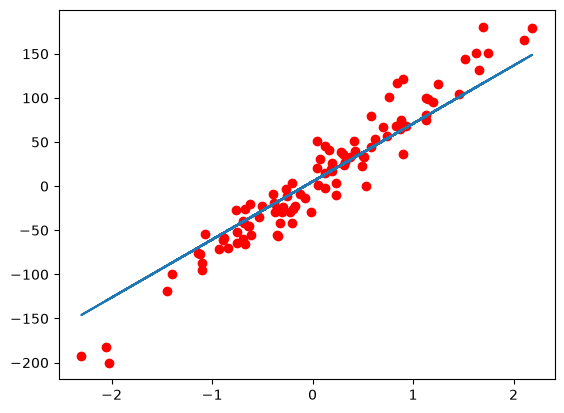

In [ ]:
# Prepare data
X_numpy, Y_numpy = datasets.make_regression(n_samples=100, n_features=1, noise=20, random_state=1)

x = torch.from_numpy(X_numpy.astype(np.float32))
y = torch.from_numpy(Y_numpy.astype(np.float32))
y = y.view(y.shape[0], 1)

n_sample,n_features = x.shape

#Model
input_size = n_features
output_size = 1

model = nn.Linear(input_size, output_size)

#loss and optimizer
learning_rate = 0.01
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate) #socahstic gradient descent

#training loop

num_epochs = 100
for epoch in range(num_epochs):

    #forward pass and loss
    y_predicted = model(x)
    loss = criterion(y_predicted, y)

    #backward pass
    loss.backward() #Back propagations and gradient calculation

    #update
    optimizer.step()

    #zero gradients
    optimizer.zero_grad()

    if (epoch+1) % 10 == 0: #every tenth step you print some information about the training process
        print(f'epoch: {epoch+1}, loss = {loss.item():.4f}')

#plot
predicted = model(x).detach().numpy() #detach() is used to remove the tensor from the computational graph, so that it can be converted to a numpy array without tracking gradients.
plt.plot(X_numpy, Y_numpy, 'ro', label='Original data')
plt.plot(X_numpy, predicted, label='Fitted line')
plt.show()

In [ ]:
import math

def extract_cg_offset(filepath): #labels    
    """
    Returns the CG offset in inches as a float (regression target).
    Forward = positive, Aft = negative, Middle = 0.00.
    Valid magnitudes: 0, 0.15, 0.30, 0.45, 0.60, 0.75.
    """
    STEP = 0.15
    MAX_OFFSET = 0.75

    cg_code = extract_cg_code_Var(filepath)      # e.g. "0.15A", "0.00M"

    direction = cg_code[-1]                  # last char: "F", "M", or "A"
    magnitude = float(cg_code[:-1])          # everything before it

    if not (0 <= magnitude <= MAX_OFFSET):
        raise ValueError(
            f"CG magnitude {magnitude} out of range (0-{MAX_OFFSET}) in {filepath}"
        )

    # Confirm it lands exactly on a valid 0.15 increment
    steps = magnitude / STEP
    if not math.isclose(steps, round(steps), abs_tol=1e-6):
        raise ValueError(
            f"CG magnitude {magnitude} is not a multiple of {STEP} in {filepath}"
        )

    # Middle should always mean exactly zero — catch mislabeled files
    # like "0.15M", which would be a contradiction in terms
    if direction == "M" and magnitude != 0:
        raise ValueError(
            f"Middle ('M') must have magnitude 0, got {magnitude} in {filepath}"
        )

    if direction == "F":
        return magnitude
    elif direction == "A":
        return -magnitude
    else:  # direction == "M"
        return 0.0
